# 07.1 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/01-time-series-basics/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


## Exercise 1

| day | value | window | 3-day mean |
|---|---|---|---|
| 1 | 12 | | — |
| 2 | 15 | | — |
| 3 | 9 | 12, 15, 9 | 12 |
| 4 | 0 | 15, 9, 0 | 8 |
| 5 | 21 | 9, 0, 21 | 10 |
| 6 | 18 | 0, 21, 18 | 13 |

In [2]:
pd.Series([12, 15, 9, 0, 21, 18]).rolling(3).mean()

0     NaN
1     NaN
2    12.0
3     8.0
4    10.0
5    13.0
dtype: float64

## Exercise 2

In [3]:
for year in [2010, 2011]:
    m = monthly[monthly.index.year == year]
    best, worst = m.idxmax(), m.idxmin()
    print(f"{year}: {len(m)} months, best {best:%b} £{m.max():,.0f}, worst {worst:%b} £{m.min():,.0f}, "
          f"ratio {m.max() / m.min():.1f}x")
print("Last month in the series:", monthly.index[-1].date())

2010: 12 months, best Nov £1,166,460, worst Feb £504,559, ratio 2.3x
2011: 11 months, best Nov £1,156,206, worst Feb £446,085, ratio 2.6x
Last month in the series: 2011-11-30


November is the best month in both years, at more than twice the worst. 2011 has only 11 months here: the series stops at the end of November because December 2011 has just four days of data, and a four-day "month" would look like a 90% collapse in sales. Always check the first and last period of a time series for partial coverage.

## Exercise 3

In [4]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
share = daily.groupby(daily.index.day_of_week).sum() / daily.sum()
share.index = [names[i] for i in share.index]
(share * 100).round(1)

Mon    16.1
Tue    18.9
Wed    17.5
Thu    21.9
Fri    15.1
Sat     0.1
Sun    10.5
Name: Revenue, dtype: float64

Thursday and Tuesday take the largest shares. Those are the days to staff up. Sunday is open but light, and Saturday is effectively closed.

## Exercise 4

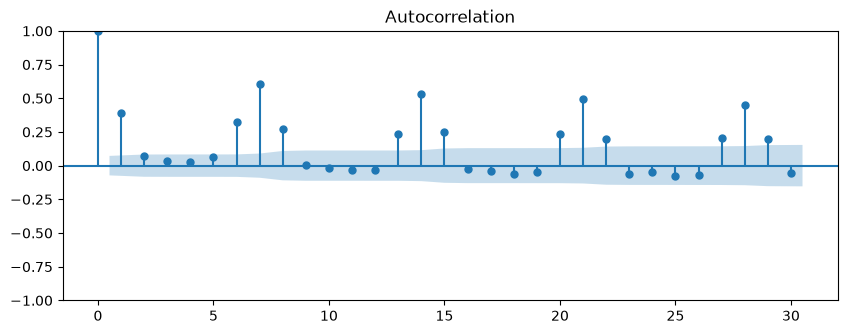

lag  1: 0.39
lag  6: 0.33
lag  7: 0.61
lag 14: 0.55


In [5]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(daily, lags=30, ax=ax); plt.show()
for k in [1, 6, 7, 14]:
    print(f"lag {k:>2}: {daily.autocorr(k):.2f}")

Lags 7, 14, 21 and 28 stand out: each day looks like the same weekday one, two, three weeks earlier. A daily model therefore needs the day of the week as a feature, and lags that are multiples of seven. Lesson 07.5 builds exactly those.